# 06 图像分类：真实手写数字与小型 CNN

输入灰度图像 → CNN 特征 → 十类 logits → Softmax 概率。你会看到像素矩阵、卷积特征图、训练曲线、混淆矩阵与失败例。
本课离线使用真实手写数字数据；从零训练，不下载权重。CPU 默认几秒到几十秒，GPU 自动兼容。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder)); break
else:
    raise FileNotFoundError("请从课程项目根目录或 notebooks 目录启动 Jupyter。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
from torch import nn
torch.set_num_threads(min(2, os.cpu_count() or 1))
DEVICE = device()
print("计算设备：", DEVICE)


计算设备： cpu


## 1. 先划分训练、验证与测试

训练集负责更新参数，验证集负责选择模型，测试集只在训练结束后评价一次。
按类别分层划分，避免某个集合缺少数字；这里没有随机增强，方便初学者跟踪输入变化。


train / val / test： 1257 270 270
输入形状 N,C,H,W： (1797, 1, 8, 8)
输入 8×8 浮点矩阵：
 [[0.   0.   0.31 0.81 0.56 0.06 0.   0.  ]
 [0.   0.   0.81 0.94 0.62 0.94 0.31 0.  ]
 [0.   0.19 0.94 0.12 0.   0.69 0.5  0.  ]
 [0.   0.25 0.75 0.   0.   0.5  0.5  0.  ]
 [0.   0.31 0.5  0.   0.   0.56 0.5  0.  ]
 [0.   0.25 0.69 0.   0.06 0.75 0.44 0.  ]
 [0.   0.12 0.88 0.31 0.62 0.75 0.   0.  ]
 [0.   0.   0.38 0.81 0.62 0.   0.   0.  ]]


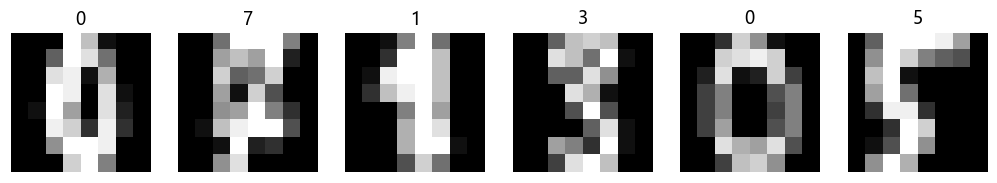

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/06_classification_inputs.png')

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from torch.utils.data import TensorDataset, DataLoader
data = load_digits()
X = torch.tensor(data.images[:, None] / 16., dtype=torch.float32)
y = torch.tensor(data.target, dtype=torch.long)
train_ids, rest_ids = train_test_split(np.arange(len(y)), test_size=.3, stratify=y.numpy(), random_state=42)
val_ids, test_ids = train_test_split(rest_ids, test_size=.5, stratify=y[rest_ids].numpy(), random_state=42)
print("train / val / test：", len(train_ids), len(val_ids), len(test_ids))
print("输入形状 N,C,H,W：", tuple(X.shape))
print("输入 8×8 浮点矩阵：\n", np.round(X[0,0].numpy(), 2))
fig, axs = plt.subplots(1, 6, figsize=(12, 3))
for ax, i in zip(axs, train_ids[:6]):
    ax.imshow(X[i,0], cmap="gray", vmin=0, vmax=1); ax.set_title(str(y[i].item())); ax.axis("off")
save_figure("06_classification_inputs.png")


## 2. 看清每一层的输入输出

第一层卷积：`[N,1,8,8] → [N,12,8,8]`；池化得到 4×4；第二层得到 24 个通道。
最后的线性层输出 10 个 logits。训练的 `CrossEntropyLoss` 内部包含 log-softmax，不要先做 Softmax 再传入它。


In [3]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1,12,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(12,24,3,padding=1), nn.ReLU())
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(24*4*4,48), nn.ReLU(), nn.Linear(48,10))
    def forward(self, x):
        return self.classifier(self.features(x))
model = DigitCNN().to(DEVICE)
example = X[:1].to(DEVICE)
with torch.no_grad():
    print("feature map：", tuple(model.features(example).shape))
    print("logits：", tuple(model(example).shape))
train_loader = DataLoader(TensorDataset(X[train_ids],y[train_ids]), batch_size=64, shuffle=True, num_workers=0)
optimizer = torch.optim.Adam(model.parameters(), lr=.003)
criterion = nn.CrossEntropyLoss()


feature map： (1, 24, 4, 4)
logits： (1, 10)


## 3. 训练，并按验证准确率保留模型

`model.train()` 用于训练；`eval()` 和 `no_grad()` 用于评价。数据和模型都移动到同一个设备。
测试集在这个单元中完全不使用。设置 `CV_DEVICE=cpu` 可强制 CPU。


最佳验证准确率：0.967


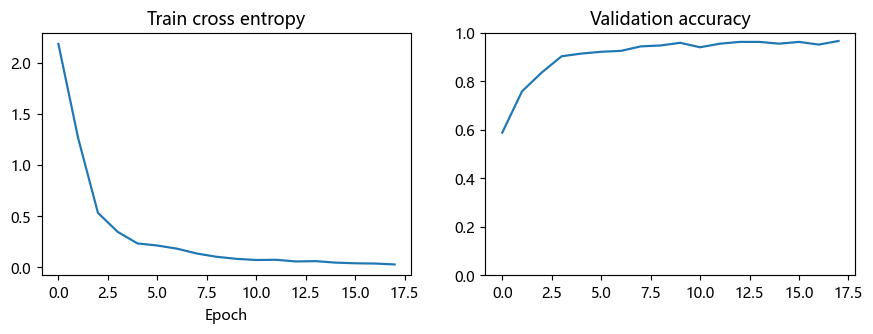

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/06_classification_training.png')

In [4]:
import copy
history, best_val, best_weights = [], -1., None
for epoch in range(18):
    model.train(); total_loss = 0.
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(); loss = criterion(model(xb),yb)
        loss.backward(); optimizer.step()
        total_loss += loss.item()*len(xb)
    model.eval()
    with torch.no_grad():
        val_accuracy = (model(X[val_ids].to(DEVICE)).argmax(1).cpu() == y[val_ids]).float().mean().item()
    history.append((total_loss/len(train_ids),val_accuracy))
    if val_accuracy > best_val:
        best_val = val_accuracy; best_weights = copy.deepcopy(model.state_dict())
model.load_state_dict(best_weights)
print(f"最佳验证准确率：{best_val:.3f}")
fig, axs = plt.subplots(1,2,figsize=(10,3))
axs[0].plot(np.array(history)[:,0]); axs[0].set_title("Train cross entropy"); axs[0].set_xlabel("Epoch")
axs[1].plot(np.array(history)[:,1]); axs[1].set_title("Validation accuracy"); axs[1].set_ylim(0,1)
save_figure("06_classification_training.png")


## 4. 单张图片：从像素到类别概率

本例是互斥的单标签十分类，因此 Softmax 后每行概率之和为 1。
最高概率并不等于模型一定正确；模型在分布外数据上仍可能错误且自信。


logits： [  4.552  -0.811  -2.215  -7.362   4.166   0.857  12.41   -6.915   0.292
 -21.148]
概率： [0.    0.    0.    0.    0.    0.    0.999 0.    0.    0.   ] ；sum= 0.99999994
第一张特征图左上角：
 [[0.253 0.265 0.   ]
 [1.315 0.    0.993]
 [0.746 1.635 0.762]]


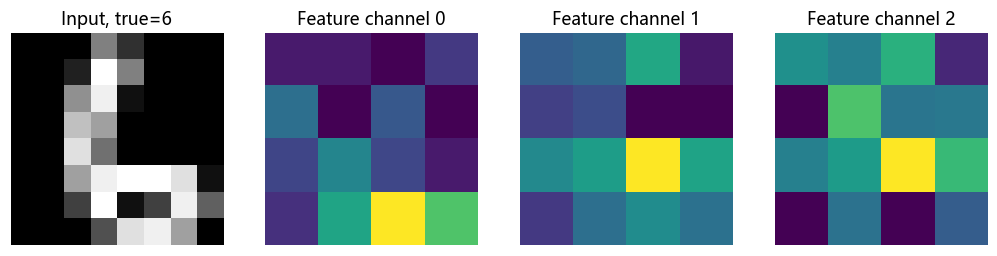

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/06_classification_features.png')

In [5]:
model.eval()
with torch.no_grad():
    logits = model(X[test_ids].to(DEVICE))
    probabilities = logits.softmax(1).cpu().numpy()
    pred = probabilities.argmax(1)
    maps = model.features(X[test_ids[:1]].to(DEVICE)).cpu().numpy()[0]
print("logits：", np.round(logits[0].cpu().numpy(),3))
print("概率：", np.round(probabilities[0],3), "；sum=", probabilities[0].sum())
print("第一张特征图左上角：\n", np.round(maps[0,:3,:3],3))
fig, axs = plt.subplots(1,4,figsize=(12,3))
axs[0].imshow(X[test_ids[0],0],cmap="gray"); axs[0].set_title(f"Input, true={y[test_ids[0]].item()}")
for i, ax in enumerate(axs[1:]): ax.imshow(maps[i],cmap="viridis"); ax.set_title(f"Feature channel {i}")
for ax in axs: ax.axis("off")
save_figure("06_classification_features.png")


## 5. 独立测试与错误分析

混淆矩阵的行是真实类别，列是预测类别。离对角线的数字越多，说明那些类别更容易互相混淆。
下方优先展示错例；若没有错例则展示普通测试样本。


独立测试准确率：0.978
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       0.96      0.96      0.96        28
           2       1.00      1.00      1.00        26
           3       1.00      1.00      1.00        28
           4       1.00      1.00      1.00        27
           5       1.00      1.00      1.00        27
           6       1.00      0.96      0.98        27
           7       0.93      1.00      0.96        27
           8       0.88      0.88      0.88        26
           9       1.00      0.96      0.98        27

    accuracy                           0.98       270
   macro avg       0.98      0.98      0.98       270
weighted avg       0.98      0.98      0.98       270



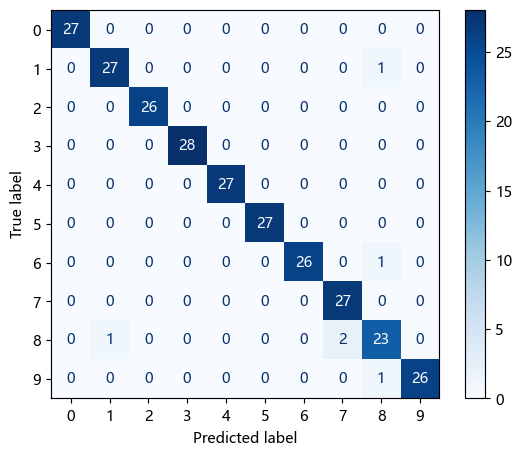

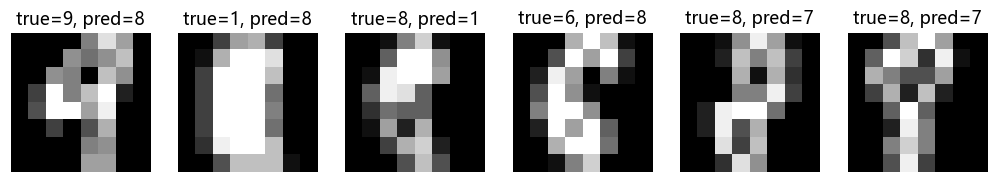

In [6]:
test_accuracy = float(np.mean(pred == y[test_ids].numpy()))
print(f"独立测试准确率：{test_accuracy:.3f}")
print(classification_report(y[test_ids], pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y[test_ids],pred,cmap="Blues")
save_figure("06_classification_confusion.png")
wrong = np.flatnonzero(pred != y[test_ids].numpy())
selected = wrong[:6] if len(wrong) else np.arange(6)
fig, axs = plt.subplots(1,len(selected),figsize=(12,3),squeeze=False)
for ax,k in zip(axs[0],selected):
    ax.imshow(X[test_ids[k],0],cmap="gray"); ax.set_title(f"true={y[test_ids[k]].item()}, pred={pred[k]}"); ax.axis("off")
save_figure("06_classification_errors.png")
assert test_accuracy > .90, "学习结果异常：检查随机种子、训练轮数与归一化。"


## 6. 自己动手与进一步阅读

1. 去掉第二个卷积层，比较运行时间、参数量和测试准确率。
2. 对测试输入加噪声或旋转，观察分布变化带来的误差；不要根据测试结果反复调整参数。
3. 改用自己的十类图片前，需要重新准备标签、划分数据并训练；这个小模型不能识别任意物体。

来源：[PyTorch 基础训练教程](https://pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html)、[CrossEntropyLoss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)、[digits 数据](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)。
